*  DSC540-T303 Data Preparation (2265-1)
*  Weeks 7 & 8 Exercises
*  David Jorgensen

# Weeks 7 & 8 Exercises

# Instructions

Complete at least 8 of the following exercises against the candy data:
- Filter out missing data
- Fill in missing data
- Remove duplicates
- Transform data using either mapping or a function
- Replace values
- Discretization and Binning
- Manipulate Strings
- Create hierarchical index
- Combine and Merge Datasets (create a new dataset from your existing data or create a relationship between the datasets)
- Reshape
- Pivot the data
- Grouping with Dicts/Series
- Grouping with Functions
- Grouping with Index Levels
- Split/Apply/Combine
- Cross Tabs
- Convert between string and date time
- Generate date range
- Frequencies and date offsets
- Convert timestamps to periods and back
- Period Frequency conversions

# Assignment

In [1]:
# Load Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Load Excel spreadsheet data
candy = pd.read_excel('./weeks_7-8_data/CANDYDATA.xlsx')
candy_hierarchy_2015 = pd.read_excel('./weeks_7-8_data/CANDY-HIERARCHY-2015-SURVEY-Responses.xlsx')
candy_hierarchy_2016 = pd.read_excel('./weeks_7-8_data/BOING-BOING-CANDY-HIERARCHY-2016-SURVEY-Responses.xlsx')
candy_hierarchy_2017 = pd.read_excel('./weeks_7-8_data/candyhierarchy2017.xlsx')

print(f'candy (aggregated):  {candy.shape}')
print(f'2015 raw survey:     {candy_hierarchy_2015.shape}')
print(f'2016 raw survey:     {candy_hierarchy_2016.shape}')
print(f'2017 raw survey:     {candy_hierarchy_2017.shape}')

candy (aggregated):  (87, 6)
2015 raw survey:     (5630, 124)
2016 raw survey:     (1259, 123)
2017 raw survey:     (2460, 120)


## 1: Manipulate Strings: Normalize Candy Column Names

The three survey years use different column naming conventions for candy ratings:
- **2015/2016**: ` [CandyName]` (leading space, wrapped in brackets)
- **2017**: `Q6 | CandyName`

We extract just the candy name from each format to build a consistent lookup dictionary.

In [2]:
def extract_candy_name_bracket(col):
    """Strip leading space + brackets: ' [Butterfinger]' -> 'Butterfinger'"""
    s = col.strip()
    if s.startswith('[') and s.endswith(']'):
        return s[1:-1].strip()
    return None

def extract_candy_name_q6(col):
    """Strip 'Q6 | ' prefix and stray tab characters."""
    if col.startswith('Q6 | '):
        return col[5:].replace('\t', ' ').strip()
    return None

# Build {candy_name: original_column} dicts
candy_cols_15 = {
    extract_candy_name_bracket(c): c
    for c in candy_hierarchy_2015.columns if extract_candy_name_bracket(c)
}
candy_cols_16 = {
    extract_candy_name_bracket(c): c
    for c in candy_hierarchy_2016.columns if extract_candy_name_bracket(c)
}
candy_cols_17 = {
    extract_candy_name_q6(c): c
    for c in candy_hierarchy_2017.columns if extract_candy_name_q6(c)
}

print(f'Candy columns found — 2015: {len(candy_cols_15)}, 2016: {len(candy_cols_16)}, 2017: {len(candy_cols_17)}')

common_candies = set(candy_cols_15) & set(candy_cols_16) & set(candy_cols_17)
print(f'Candies common to all 3 years: {len(common_candies)}')
print('\nSample normalized names:', sorted(common_candies)[:8])

Candy columns found — 2015: 95, 2016: 100, 2017: 103
Candies common to all 3 years: 75

Sample normalized names: ['100 Grand Bar', 'Any full-sized candy bar', 'Black Jacks', 'Bottle Caps', 'Broken glow stick', 'Butterfinger', 'Cadbury Creme Eggs', 'Candy Corn']


## 2: Filter Out Missing Data

Some respondents submitted the survey without rating any candy. These rows are useless for analysis and should be dropped.

In [3]:
def filter_no_candy_responses(df, candy_dict):
    """Drop rows where every candy column is NaN."""
    cols = list(candy_dict.values())
    before = len(df)
    df_out = df[df[cols].notna().any(axis=1)].copy()
    dropped = before - len(df_out)
    print(f'  Dropped {dropped} rows with no candy ratings ({before} -> {len(df_out)})')
    return df_out

print('Filtering empty candy rows:')
c15 = filter_no_candy_responses(candy_hierarchy_2015, candy_cols_15)
c16 = filter_no_candy_responses(candy_hierarchy_2016, candy_cols_16)
c17 = filter_no_candy_responses(candy_hierarchy_2017, candy_cols_17)

Filtering empty candy rows:
  Dropped 97 rows with no candy ratings (5630 -> 5533)
  Dropped 3 rows with no candy ratings (1259 -> 1256)
  Dropped 657 rows with no candy ratings (2460 -> 1803)


## 3: Remove Duplicates

In [4]:
for name, df in [('2015', c15), ('2016', c16), ('2017', c17)]:
    before = len(df)
    df.drop_duplicates(inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f'{name}: removed {before - len(df)} duplicate rows, {len(df)} remain')

2015: removed 0 duplicate rows, 5533 remain
2016: removed 0 duplicate rows, 1256 remain
2017: removed 0 duplicate rows, 1803 remain


## 4: Convert Between String and Datetime / Generate Date Range

The 2015 and 2016 surveys include a `Timestamp` column stored as a string. We parse it to `datetime64` and then demonstrate generating a date range spanning the survey collection window.

In [5]:
c15['Timestamp'] = pd.to_datetime(c15['Timestamp'])
c16['Timestamp'] = pd.to_datetime(c16['Timestamp'])

print('2015 survey window:')
print(f'  Start: {c15["Timestamp"].min()}')
print(f'  End:   {c15["Timestamp"].max()}')

print('\n2016 survey window:')
print(f'  Start: {c16["Timestamp"].min()}')
print(f'  End:   {c16["Timestamp"].max()}')

# Generate a daily date range covering the 2015 survey period
survey_range_2015 = pd.date_range(
    start=c15['Timestamp'].min().normalize(),
    end=c15['Timestamp'].max().normalize(),
    freq='D'
)
print(f'\n2015 survey spanned {len(survey_range_2015)} calendar days:')
print(survey_range_2015)

2015 survey window:
  Start: 2015-10-23 08:46:20.451000
  End:   2015-10-31 06:41:31.904000

2016 survey window:
  Start: 2016-10-24 05:09:23.033000
  End:   2016-10-30 17:06:45.660000

2015 survey spanned 9 calendar days:
DatetimeIndex(['2015-10-23', '2015-10-24', '2015-10-25', '2015-10-26',
               '2015-10-27', '2015-10-28', '2015-10-29', '2015-10-30',
               '2015-10-31'],
              dtype='datetime64[ns]', freq='D')


## 5: Convert Timestamps to Periods / Period Frequency Conversions

Convert timestamps to daily periods, then roll up to weekly frequency to see which week got the most responses.

In [6]:
# Convert to daily Period
c15['survey_day'] = c15['Timestamp'].dt.to_period('D')
c16['survey_day'] = c16['Timestamp'].dt.to_period('D')

# Convert daily Period to weekly (period frequency conversion)
c15['survey_week'] = c15['survey_day'].dt.to_timestamp().dt.to_period('W')
c16['survey_week'] = c16['survey_day'].dt.to_timestamp().dt.to_period('W')

print('2015 responses by week:')
print(c15['survey_week'].value_counts().sort_index())

print('\n2016 responses by week:')
print(c16['survey_week'].value_counts().sort_index())

# Convert Period back to Timestamp to demonstrate round-trip
c15['survey_day_ts'] = c15['survey_day'].dt.to_timestamp()
print('\nPeriod -> Timestamp round-trip (first 3 rows):')
print(c15[['Timestamp', 'survey_day', 'survey_day_ts']].head(3))

2015 responses by week:
survey_week
2015-10-19/2015-10-25    1599
2015-10-26/2015-11-01    3934
Freq: W-SUN, Name: count, dtype: int64

2016 responses by week:
survey_week
2016-10-24/2016-10-30    1256
Freq: W-SUN, Name: count, dtype: int64

Period -> Timestamp round-trip (first 3 rows):
                Timestamp  survey_day survey_day_ts
0 2015-10-23 08:46:20.451  2015-10-23    2015-10-23
1 2015-10-23 08:46:51.583  2015-10-23    2015-10-23
2 2015-10-23 08:47:34.285  2015-10-23    2015-10-23


## 6: Discretization and Binning: Age Groups

The age column is self-reported and contains garbage values (e.g., `89999999999999995805696` in 2015). We clean it with `pd.to_numeric` and clip to plausible range [5, 120], then bin into five groups.

In [7]:
AGE_BINS = [0, 17, 30, 45, 60, 120]
AGE_LABELS = ['Under 18', '18-30', '31-45', '46-60', '60+']

def clean_and_bin_age(df, col):
    age = pd.to_numeric(df[col], errors='coerce')
    df['age_clean'] = age.where((age >= 5) & (age <= 120), np.nan)
    df['age_group'] = pd.cut(df['age_clean'], bins=AGE_BINS, labels=AGE_LABELS)

clean_and_bin_age(c15, 'How old are you?')
clean_and_bin_age(c16, 'How old are you?')
clean_and_bin_age(c17, 'Q3: AGE')

for name, df in [('2015', c15), ('2016', c16), ('2017', c17)]:
    invalid = df['age_clean'].isna().sum()
    print(f'{name} — {invalid} invalid/missing ages filtered. Age group distribution:')
    print(df['age_group'].value_counts().sort_index().to_string())
    print()

2015 — 288 invalid/missing ages filtered. Age group distribution:
age_group
Under 18     137
18-30       1478
31-45       2543
46-60        921
60+          166

2016 — 69 invalid/missing ages filtered. Age group distribution:
age_group
Under 18     21
18-30       187
31-45       596
46-60       341
60+          42

2017 — 58 invalid/missing ages filtered. Age group distribution:
age_group
Under 18     40
18-30       189
31-45       834
46-60       564
60+         118



## 7: Replace Values: Standardize Demographic Column Names

Each year uses different column names for the same demographic data. We create standardized columns (`going_out`, `gender`, `country`, `state`, `dress`) so all three years can be combined.

In [8]:
# 2015: going_out, no gender/country/state columns
c15['going_out'] = c15['Are you going actually going trick or treating yourself?']
c15['gender']    = np.nan
c15['country']   = np.nan
c15['state']     = np.nan
c15['dress']     = c15['"That dress* that went viral early this year - when I first saw it, it was ________"']
c15['year']      = 2015

# 2016
c16['going_out'] = c16['Are you going actually going trick or treating yourself?']
c16['gender']    = c16['Your gender:']
c16['country']   = c16['Which country do you live in?']
c16['state']     = c16['Which state, province, county do you live in?']
c16['dress']     = c16['"That dress* that went viral a few years back - when I first saw it, it was ________"']
c16['year']      = 2016

# 2017 — uses Q-numbered columns
c17['going_out'] = c17['Q1: GOING OUT?']
c17['gender']    = c17['Q2: GENDER']
c17['country']   = c17['Q4: COUNTRY']
c17['state']     = c17['Q5: STATE, PROVINCE, COUNTY, ETC']
c17['dress']     = c17['Q10: DRESS']
c17['year']      = 2017

# Verify going_out values are consistent across years
for name, df in [('2015', c15), ('2016', c16), ('2017', c17)]:
    print(f'{name} going_out values: {df["going_out"].value_counts().to_dict()}')

2015 going_out values: {'No': 5019, 'Yes': 514}
2016 going_out values: {'No': 1118, 'Yes': 138}
2017 going_out values: {'No': 1500, 'Yes': 239}


## 8: Fill In Missing Data

**Important note on 2015 NaN values:** In 2015, the survey did not offer a "MEH" option — respondents could only choose JOY or DESPAIR. A `NaN` in a 2015 candy column means the respondent did not have a strong opinion (or skipped), **not** that they chose MEH. We leave these as `NaN` rather than imputing "MEH" to avoid distorting longitudinal comparisons.

We do fill `going_out` NaN values with `'No response'` since it is a demographic field used for grouping.

In [9]:
# Fill missing going_out with 'No response'
for df in [c15, c16, c17]:
    df['going_out'] = df['going_out'].fillna('No response')

# Show NaN rate in candy columns per year to illustrate scale
candy_cols_all = {
    2015: candy_cols_15,
    2016: candy_cols_16,
    2017: candy_cols_17,
}
for year, (df, cols) in zip([2015,2016,2017], zip([c15,c16,c17],
                             [candy_cols_15, candy_cols_16, candy_cols_17])):
    total_cells = len(df) * len(cols)
    nan_cells = df[list(cols.values())].isna().sum().sum()
    pct = nan_cells / total_cells * 100
    note = ' (no MEH option)' if year == 2015 else ''
    print(f'{year}: {nan_cells:,}/{total_cells:,} candy cells are NaN ({pct:.1f}%){note}')

2015: 47,128/525,635 candy cells are NaN (9.0%) (no MEH option)
2016: 7,310/125,600 candy cells are NaN (5.8%)
2017: 10,154/185,709 candy cells are NaN (5.5%)


## 9: Transform Data with Mapping: Encode Ratings as Integers

Map text ratings to numeric values so arithmetic (net feelies = JOY − DESPAIR) is straightforward. MEH = 0 acts as a neutral middle value.

In [10]:
RATING_MAP = {'JOY': 1, 'MEH': 0, 'DESPAIR': -1}

def apply_rating_map(df, candy_dict):
    """Add '_num' suffixed columns with integer-encoded ratings."""
    for name, col in candy_dict.items():
        df[col + '_num'] = df[col].map(RATING_MAP)

apply_rating_map(c15, candy_cols_15)
apply_rating_map(c16, candy_cols_16)
apply_rating_map(c17, candy_cols_17)

# Verify: check Snickers numeric encoding for 2017
snickers_col = candy_cols_17.get('Snickers')
if snickers_col:
    check = c17[[snickers_col, snickers_col + '_num']].dropna(subset=[snickers_col]).head(6)
    print('Snickers rating mapping (2017):')
    print(check.to_string(index=False))

Snickers rating mapping (2017):
Q6 | Snickers  Q6 | Snickers_num
          MEH                0.0
          JOY                1.0
          JOY                1.0
          MEH                0.0
          JOY                1.0
          MEH                0.0


## 10: Reshape (Melt): Wide --> Long Format

Each survey year is currently in **wide format** with one column per candy. We melt to **long format** (one row per respondent-candy pair) so all three years can be stacked and analyzed uniformly.

In [11]:
META_COLS = ['year', 'going_out', 'gender', 'country', 'state',
             'age_clean', 'age_group']

# Assign a stable respondent_id to each year
c15['respondent_id'] = range(len(c15))
c16['respondent_id'] = range(len(c16))
c17['respondent_id'] = c17['Internal ID']

def melt_to_long(df, candy_dict, meta_cols):
    """Melt candy columns to long form; drop NaN ratings (not rated)."""
    rename_map = {v: k for k, v in candy_dict.items()}
    df2 = df[['respondent_id'] + meta_cols + list(candy_dict.values())].rename(columns=rename_map)
    candy_names = list(candy_dict.keys())
    long = df2.melt(
        id_vars=['respondent_id'] + meta_cols,
        value_vars=candy_names,
        var_name='candy',
        value_name='rating'
    )
    long = long.dropna(subset=['rating'])
    long['rating_num'] = long['rating'].map(RATING_MAP)
    return long

long_15 = melt_to_long(c15, candy_cols_15, META_COLS)
long_16 = melt_to_long(c16, candy_cols_16, META_COLS)
long_17 = melt_to_long(c17, candy_cols_17, META_COLS)

print('Long-form shapes after melt:')
print(f'  2015: {long_15.shape[0]:,} rows  ({c15.shape[0]:,} respondents × up to {len(candy_cols_15)} candies)')
print(f'  2016: {long_16.shape[0]:,} rows  ({c16.shape[0]:,} respondents × up to {len(candy_cols_16)} candies)')
print(f'  2017: {long_17.shape[0]:,} rows  ({c17.shape[0]:,} respondents × up to {len(candy_cols_17)} candies)')
print()
print(long_15.head(4))

Long-form shapes after melt:
  2015: 478,507 rows  (5,533 respondents × up to 95 candies)
  2016: 118,290 rows  (1,256 respondents × up to 100 candies)
  2017: 175,555 rows  (1,803 respondents × up to 103 candies)

   respondent_id  year going_out  gender  country  state  age_clean age_group  \
0              0  2015        No     NaN      NaN    NaN       35.0     31-45   
1              1  2015        No     NaN      NaN    NaN       41.0     31-45   
2              2  2015        No     NaN      NaN    NaN       33.0     31-45   
3              3  2015        No     NaN      NaN    NaN       31.0     31-45   

          candy   rating  rating_num  
0  Butterfinger      JOY           1  
1  Butterfinger      JOY           1  
2  Butterfinger  DESPAIR          -1  
3  Butterfinger      JOY           1  


## 11: Combine and Merge Datasets

Stack the three long-form DataFrames into a single combined dataset covering all three survey years.

In [12]:
combined = pd.concat([long_15, long_16, long_17], ignore_index=True)

print(f'Combined dataset: {combined.shape[0]:,} rows × {combined.shape[1]} columns')
print(f'Years present: {sorted(combined["year"].unique())}')
print(f'Unique candies: {combined["candy"].nunique()}')
print()
print(combined.dtypes)

Combined dataset: 772,352 rows × 11 columns
Years present: [np.int64(2015), np.int64(2016), np.int64(2017)]
Unique candies: 125

respondent_id       int64
year                int64
going_out          object
gender             object
country            object
state              object
age_clean         float64
age_group        category
candy              object
rating             object
rating_num          int64
dtype: object


## 12: Create Hierarchical Index

Set a MultiIndex of `(year, respondent_id)` so individual respondents can be looked up per-year efficiently.

In [13]:
combined_hi = combined.set_index(['year', 'respondent_id'])

print('MultiIndex levels:')
print(f'  Level 0 (year):         {combined_hi.index.get_level_values(0).unique().tolist()}')
print(f'  Level 1 (respondent_id) unique count: {combined_hi.index.get_level_values(1).nunique()}')
print()

# Look up all ratings for respondent 0 in 2015
print('All candy ratings for respondent 0 in 2015:')
print(combined_hi.loc[(2015, 0), ['candy', 'rating']].head(10))

MultiIndex levels:
  Level 0 (year):         [2015, 2016, 2017]
  Level 1 (respondent_id) unique count: 7336

All candy ratings for respondent 0 in 2015:
                                                                candy   rating
year respondent_id                                                            
2015 0                                                   Butterfinger      JOY
     0              Anonymous brown globs that come in black and o...  DESPAIR
     0                                       Any full-sized candy bar      JOY
     0                      Brach products (not including candy corn)  DESPAIR
     0                                                     Bubble Gum  DESPAIR
     0                                             Cadbury Creme Eggs  DESPAIR
     0              Vials of pure high fructose corn syrup, for ma...  DESPAIR
     0              Candy that is clearly just the stuff given out...  DESPAIR
     0                           Cash, or other forms of

## 13: Split / Apply / Combine: Net Feelies Per Candy Per Year

Net Feelies = # JOY votes − # DESPAIR votes. We `groupby` candy and year, then apply a custom aggregation.

In [14]:
def net_feelies(group):
    joy     = (group == 'JOY').sum()
    despair = (group == 'DESPAIR').sum()
    return joy - despair

nf_by_year = (
    combined
    .groupby(['year', 'candy'])['rating']
    .apply(net_feelies)
    .rename('net_feelies')
    .reset_index()
)

print('Net Feelies computed for', len(nf_by_year), 'candy-year combinations')
print()

# Top 5 candies for each year
for yr in [2015, 2016, 2017]:
    top = nf_by_year[nf_by_year.year == yr].nlargest(5, 'net_feelies')
    print(f'{yr} top 5:')
    print(top[['candy', 'net_feelies']].to_string(index=False))
    print()

Net Feelies computed for 298 candy-year combinations

2015 top 5:
                     candy  net_feelies
  Any full-sized candy bar         4603
Reese’s Peanut Butter Cups         4375
                   Kit Kat         4340
                      Twix         4041
                  Snickers         4006

2016 top 5:
                               candy  net_feelies
            Any full-sized candy bar         1037
Cash, or other forms of legal tender          948
                             Kit Kat          920
          Reese’s Peanut Butter Cups          906
                                Twix          839

2017 top 5:
                               candy  net_feelies
            Any full-sized candy bar         1542
          Reese’s Peanut Butter Cups         1403
                             Kit Kat         1395
Cash, or other forms of legal tender         1374
                                Twix         1342



## 14: Pivot the Data

Pivot the net feelies data so candies are rows and years are columns, making year-over-year comparison easy.

In [15]:
nf_pivot = nf_by_year.pivot(index='candy', columns='year', values='net_feelies')
nf_pivot.columns.name = None

# Only show candies present in all 3 years
nf_pivot_common = nf_pivot.dropna()

print(f'Pivot table: {nf_pivot_common.shape[0]} candies × {nf_pivot_common.shape[1]} years')
print()

# Sort by 2017 net feelies
print('Top 10 candies by 2017 Net Feelies (all-year comparison):')
print(nf_pivot_common.sort_values(2017, ascending=False).head(10).to_string())

print()
print('Bottom 10 candies by 2017 Net Feelies:')
print(nf_pivot_common.sort_values(2017, ascending=True).head(10).to_string())

Pivot table: 75 candies × 3 years

Top 10 candies by 2017 Net Feelies (all-year comparison):
                                        2015    2016    2017
candy                                                       
Any full-sized candy bar              4603.0  1037.0  1542.0
Reese’s Peanut Butter Cups            4375.0   906.0  1403.0
Kit Kat                               4340.0   920.0  1395.0
Cash, or other forms of legal tender  3419.0   948.0  1374.0
Twix                                  4041.0   839.0  1342.0
Snickers                              4006.0   832.0  1320.0
Tolberone something or other          2797.0   802.0  1236.0
Lindt Truffle                         2833.0   804.0  1179.0
Peanut M&M’s                          3299.0   741.0  1170.0
Nestle Crunch                         3172.0   666.0  1086.0

Bottom 10 candies by 2017 Net Feelies:
                                                                          2015    2016    2017
candy                                   

## 15: Grouping with Functions: Top Candy by Age Group

Group respondents by age bucket, then apply a function to find the highest net-feelie candy for each group.

In [16]:
def top_candy_by_net_feelies(group):
    """Return the candy with the highest net feelies within a group."""
    nf = group.groupby('candy')['rating'].apply(
        lambda s: (s == 'JOY').sum() - (s == 'DESPAIR').sum()
    )
    if nf.empty:
        return pd.Series({'top_candy': None, 'net_feelies': np.nan})
    best = nf.idxmax()
    return pd.Series({'top_candy': best, 'net_feelies': nf[best]})

# Use the combined df (drop rows with unknown age group)
age_candy = (
    combined.dropna(subset=['age_group'])
    .groupby('age_group', observed=True)
    .apply(top_candy_by_net_feelies)
)

print('Favorite candy by age group:')
print(age_candy.to_string())

Favorite candy by age group:
                                      top_candy  net_feelies
age_group                                                   
Under 18   Cash, or other forms of legal tender          174
18-30                  Any full-sized candy bar         1614
31-45                  Any full-sized candy bar         3402
46-60                  Any full-sized candy bar         1447
60+                    Any full-sized candy bar          239


## 16: Grouping with Index Levels: Net Feelies via MultiIndex

Using the hierarchical-indexed DataFrame, group by the `year` index level without resetting the index.

In [17]:
# Add candy as a third level and rating_num as a value column
combined_hi2 = combined.set_index(['year', 'candy', 'respondent_id'])

# Group by year level (level=0) and candy level (level=1), sum rating_num
nf_index_levels = (
    combined_hi2['rating_num']
    .groupby(level=['year', 'candy'])
    .sum()
    .rename('net_feelies')
)

print('Net Feelies via index-level groupby (first 10):')
print(nf_index_levels.sort_values(ascending=False).head(10))

Net Feelies via index-level groupby (first 10):
year  candy                               
2015  Any full-sized candy bar                4603
      Reese’s Peanut Butter Cups              4375
      Kit Kat                                 4340
      Twix                                    4041
      Snickers                                4006
      Cash, or other forms of legal tender    3419
      Peanut M&M’s                            3299
      Regular M&Ms                            3284
      Nestle Crunch                           3172
      Butterfinger                            3011
Name: net_feelies, dtype: int64


## 17: Cross Tabs

Cross-tabulate trick-or-treating status (`going_out`) against the dress perception question (`dress`) to see if there's a relationship between Halloween engagement and how people perceived the viral dress.

In [18]:
# Build a per-respondent DataFrame (before melt) from each year
respondents_15 = c15[['going_out', 'dress', 'gender', 'age_group', 'year']].copy()
respondents_16 = c16[['going_out', 'dress', 'gender', 'age_group', 'year']].copy()
respondents_17 = c17[['going_out', 'dress', 'gender', 'age_group', 'year']].copy()

all_respondents = pd.concat([respondents_15, respondents_16, respondents_17], ignore_index=True)

# Drop rows without dress answer or going_out
crosstab_data = all_respondents.dropna(subset=['dress', 'going_out'])
crosstab_data = crosstab_data[crosstab_data['going_out'].isin(['Yes', 'No'])]

xtab = pd.crosstab(
    crosstab_data['going_out'],
    crosstab_data['dress'],
    margins=True,
    normalize='index'  # show row proportions
).round(3)

print('Cross-tab: going trick-or-treating vs. dress perception (row proportions):')
print(xtab)

Cross-tab: going trick-or-treating vs. dress perception (row proportions):
dress      Blue and black  White and gold
going_out                                
No                  0.502           0.498
Yes                 0.481           0.519
All                 0.500           0.500


## 18: Q10: The Dress (Categorical Analysis Across Years)

Examine how dress perception shifted year-over-year. The dress went viral in early 2015, so by 2016-2017 it was a nostalgic question.

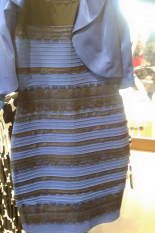

Dress perception by year (count + %):
      Blue and black  White and gold  Blue and black (%)  White and gold (%)
year                                                                        
2015            2900            2209                56.8                43.2
2016             483             728                39.9                60.1
2017             634            1079                37.0                63.0


In [19]:
from IPython.display import Image, display
display(Image('./weeks_7-8_data/10-dress.png'))

dress_by_year = (
    all_respondents
    .dropna(subset=['dress'])
    .groupby(['year', 'dress'])
    .size()
    .unstack(fill_value=0)
)

# Add proportion columns
dress_totals = dress_by_year.sum(axis=1)
dress_pct = dress_by_year.div(dress_totals, axis=0).round(3) * 100
dress_pct.columns = [f'{c} (%)' for c in dress_pct.columns]

dress_summary = dress_by_year.join(dress_pct)
print('Dress perception by year (count + %):')
print(dress_summary.to_string())

## 19: Q12: Media Preference (2016 Text + 2017 Checkboxes + Click Coordinates)

The media preference question was asked differently in each year:
- **2016**: Single free-text dropdown (one answer stored in one column)
- **2017**: Four separate checkbox columns (one per website) plus click coordinates in the image

We normalize both into a single `media_choice` column. For 2017, click coordinates are parsed and classified into quadrants based on where each site appears in `12-websites.png` (verified by correlating checkbox selections with coordinate clusters).

Website thumbnails:


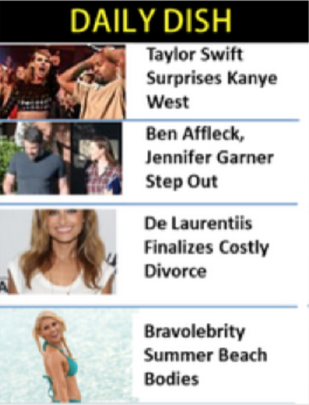

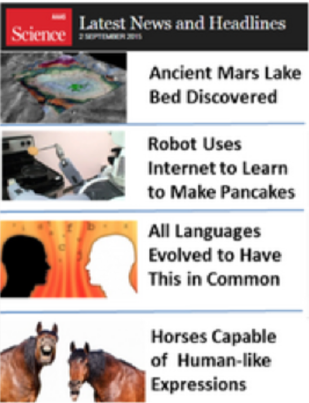

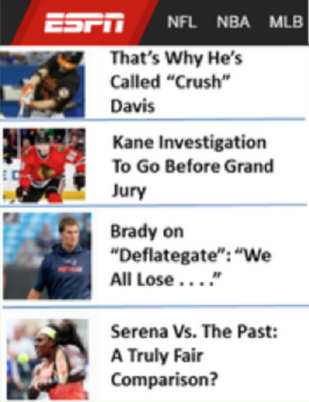

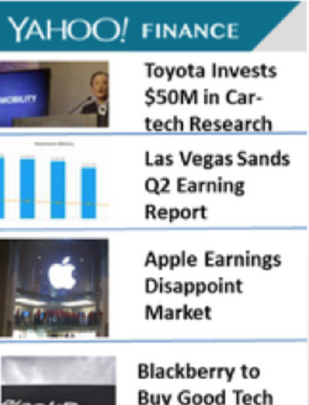

Full website image (with click coordinates, ~0-100 scale):


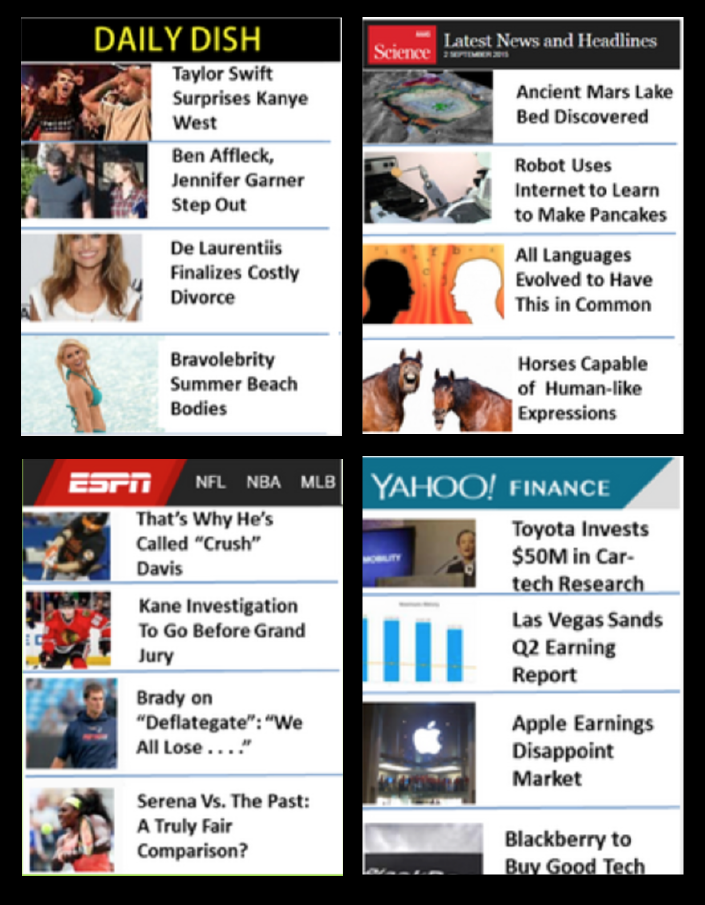

In [20]:
from IPython.display import Image, display

print('Website thumbnails:')
for img in ['12-1-dailydish.png','12-2-science.png','12-3-espn.png','12-4-yahoo.png']:
    display(Image(f'./weeks_7-8_data/{img}'))

print('Full website image (with click coordinates, ~0-100 scale):')
display(Image('./weeks_7-8_data/12-websites.png'))

In [21]:
# ---- 2016: text column -> standardized label ----
media_label_map_16 = {
    'Daily Dish':                              'Daily Dish',
    'Science: Latest News and Headlines':      'Science',
    'ESPN':                                    'ESPN',
    'YAHOO! Finance.':                         'Yahoo',
}

media_col_16 = 'When you see the above image of the 4 different websites, which one would you most likely check out (please be honest).'
c16['media_choice'] = c16[media_col_16].map(media_label_map_16)

print('2016 media choices:')
print(c16['media_choice'].value_counts())

print()

2016 media choices:
media_choice
Science       1004
ESPN            95
Daily Dish      79
Yahoo           42
Name: count, dtype: int64



In [22]:
# ---- 2017: checkbox columns + click coordinates ----
#
# Quadrant mapping verified by cross-referencing checkbox selections with
# mean click coordinates:
#   Daily Dish: x≈27, y≈25  -> top-left    (x<50, y<50)
#   Science:    x≈74, y≈23  -> top-right   (x≥50, y<50)
#   ESPN:       x≈27, y≈71  -> bottom-left (x<50, y≥50)
#   Yahoo:      x≈75, y≈70  -> bottom-right(x≥50, y≥50)

def parse_click_coords(series):
    parsed = series.str.extract(r'\((\d+),\s*(\d+)\)')
    return parsed.rename(columns={0: 'click_x', 1: 'click_y'}).astype(float)

def classify_website(row):
    if pd.isna(row['click_x']):
        return np.nan
    x, y = row['click_x'], row['click_y']
    if   x < 50 and y < 50:  return 'Daily Dish'
    elif x >= 50 and y < 50: return 'Science'
    elif x < 50 and y >= 50: return 'ESPN'
    else:                    return 'Yahoo'

click_coords = parse_click_coords(c17['Click Coordinates (x, y)'])
c17['click_x'] = click_coords['click_x']
c17['click_y'] = click_coords['click_y']
c17['media_choice_coords'] = click_coords.apply(classify_website, axis=1)

# Also derive from checkboxes (primary signal; coords are the fallback verification)
media_checkbox_map = {
    'Q12: MEDIA [Daily Dish]': 'Daily Dish',
    'Q12: MEDIA [Science]':    'Science',
    'Q12: MEDIA [ESPN]':       'ESPN',
    'Q12: MEDIA [Yahoo]':      'Yahoo',
}

def derive_media_choice(row):
    for col, label in media_checkbox_map.items():
        if row[col] == 1.0:
            return label
    return np.nan

c17['media_choice'] = c17.apply(derive_media_choice, axis=1)

print('2017 media choices (from checkboxes):')
print(c17['media_choice'].value_counts())

print('\n2017 media choices (from click coordinates):')
print(c17['media_choice_coords'].value_counts())

2017 media choices (from checkboxes):
media_choice
Science       1359
ESPN            99
Daily Dish      85
Yahoo           67
Name: count, dtype: int64

2017 media choices (from click coordinates):
media_choice_coords
Science       1351
ESPN            98
Daily Dish      86
Yahoo           67
Name: count, dtype: int64


In [23]:
# ---- Combine 2016 + 2017 media data ----
media_16 = c16[['media_choice']].assign(year=2016)
media_17 = c17[['media_choice']].assign(year=2017)
media_all = pd.concat([media_16, media_17], ignore_index=True)

media_pivot = (
    media_all.dropna(subset=['media_choice'])
    .groupby(['year', 'media_choice'])
    .size()
    .unstack(fill_value=0)
)

print('Media preference count by year:')
print(media_pivot)

# Normalize to proportions
media_pct = media_pivot.div(media_pivot.sum(axis=1), axis=0).round(3) * 100
print('\nMedia preference (%) by year:')
print(media_pct)

Media preference count by year:
media_choice  Daily Dish  ESPN  Science  Yahoo
year                                          
2016                  79    95     1004     42
2017                  85    99     1359     67

Media preference (%) by year:
media_choice  Daily Dish  ESPN  Science  Yahoo
year                                          
2016                 6.5   7.8     82.3    3.4
2017                 5.3   6.1     84.4    4.2


## 20: Grouping with Dicts/Series: Candy Category Aggregation

Map candies to broad categories using a dict, then aggregate net feelies by category.

In [24]:
candy_category_map = {
    'Snickers':                        'Chocolate',
    'Milky Way':                        'Chocolate',
    'Reese\'s Peanut Butter Cups':      'Chocolate',
    'Hershey\'s Dark Chocolate':        'Chocolate',
    'Hershey\'s Milk Chocolate':        'Chocolate',
    'Kit Kat':                          'Chocolate',
    'Twix':                             'Chocolate',
    'Three Musketeers':                 'Chocolate',
    'Nestle Crunch':                    'Chocolate',
    'Skittles':                         'Fruity/Chewy',
    'Starburst':                        'Fruity/Chewy',
    'Gummy Bears straight up':          'Fruity/Chewy',
    'Swedish Fish':                     'Fruity/Chewy',
    'Mike and Ike':                     'Fruity/Chewy',
    'Sourpatch Kids (i.e. abominations of nature)': 'Fruity/Chewy',
    'Candy Corn':                       'Seasonal/Novelty',
    'Pencils':                          'Non-Candy',
    'Healthy Fruit':                    'Non-Candy',
    'White Bread':                      'Non-Candy',
    'Whole Wheat anything':             'Non-Candy',
    'Dental paraphenalia':              'Non-Candy',
    'Kale smoothie':                    'Non-Candy',
    'Cash, or other forms of legal tender': 'Non-Candy',
    'Nerds':                            'Sugar/Hard',
    'Pixy Stix':                        'Sugar/Hard',
    'Lollipops':                        'Sugar/Hard',
    'LemonHeads':                       'Sugar/Hard',
    'Sweet Tarts':                      'Sugar/Hard',
    'Hard Candy':                       'Sugar/Hard',
}

# Map categories onto combined df
combined['category'] = combined['candy'].map(candy_category_map)

# Group by category using the mapping Series
cat_nf = (
    combined.dropna(subset=['category'])
    .groupby('category')['rating_num']
    .agg(['sum', 'count', 'mean'])
    .rename(columns={'sum': 'net_feelies', 'count': 'total_ratings', 'mean': 'avg_rating'})
    .sort_values('avg_rating', ascending=False)
    .round(3)
)

print('Net Feelies by candy category:')
print(cat_nf)

Net Feelies by candy category:
                  net_feelies  total_ratings  avg_rating
category                                                
Chocolate               34083          52396       0.650
Fruity/Chewy             8924          38387       0.232
Sugar/Hard                729          43088       0.017
Seasonal/Novelty        -1500           8260      -0.182
Non-Candy              -30055          56548      -0.531


## 21: Frequencies and Date Offsets: Response Rate by Hour of Day

Use date offsets and `dt.floor` to round timestamps to the hour and count submission frequency.

In [25]:
# Extract hour from timestamps (2015 and 2016 only — 2017 has no timestamp)
ts_15 = c15['Timestamp'].dt.floor('h').value_counts().sort_index()
ts_16 = c16['Timestamp'].dt.floor('h').value_counts().sort_index()

# Resample to hourly counts to see submission surge after publication
print('2015 peak submission hours (top 5):')
print(ts_15.nlargest(5))

print('\n2016 peak submission hours (top 5):')
print(ts_16.nlargest(5))

# Apply a business-day offset to find the next business day after peak
from pandas.tseries.offsets import BDay
peak_15 = ts_15.idxmax()
print(f'\n2015 peak hour: {peak_15}')
print(f'Next business day after peak: {peak_15 + BDay(1)}')

2015 peak submission hours (top 5):
Timestamp
2015-10-28 19:00:00    389
2015-10-28 14:00:00    275
2015-10-28 17:00:00    267
2015-10-28 18:00:00    266
2015-10-28 20:00:00    241
Name: count, dtype: int64

2016 peak submission hours (top 5):
Timestamp
2016-10-24 06:00:00    96
2016-10-24 07:00:00    91
2016-10-24 08:00:00    77
2016-10-24 09:00:00    66
2016-10-24 05:00:00    65
Name: count, dtype: int64

2015 peak hour: 2015-10-28 19:00:00
Next business day after peak: 2015-10-29 19:00:00


## Summary

| # | Exercise | What it does |
| - | -------- | ------------ |
| 1	| Manipulate Strings | Extract candy names from `[Name]` and \`Q6 |
| 2	| Filter Missing Data | Drop rows where respondent rated zero candies |
| 3	| Remove Duplicates | Drop duplicate rows |
| 4 | Convert Timestamps / Generate Date Range | Parse `Timestamp` strings to `datetime64`; build daily date range over survey window |
| 5 | Timestamps --> Periods / Period Frequency Conversions	| Day periods --> week periods; round-trip back to timestamps |
| 6 | Discretization and Binning | Clean garbage ages (e.g. `8.9e22`), bin into Under 18 / 18-30 / 31-45 / 46-60 / 60+ |
| 7	| Replace Values | Standardize column names (`going_out`, `gender`, etc.) across all 3 years |
| 8 | Fill In Missing Data | Fill `going_out` NaN; explain why 2015 candy NaN ≠ "MEH" |
| 9 | Transform with Mapping | "JOY" = `1`, "MEH" = `0`, "DESPAIR" = `-1` |
| 10 | Reshape (Melt) | Wide --> long: 95-103 candy columns --> one row per respondent-candy pair (772k rows total) |
| 11 | Combine and Merge | `pd.concat` all three years into one long dataset |
| 12 | Hierarchical Index | MultiIndex `(year, respondent_id)`; per-respondent lookup |
| 13 | Split/Apply/Combine | `groupby(year, candy)` --> custom `net_feelies` function |
| 14 | Pivot | Candy times year net feelies table; top/bottom 10 by 2017 score |
| 15 | Grouping with Functions | Custom function finds top candy per age group |
| 16 | Grouping with Index Levels | `groupby(level=['year','candy'])` on MultiIndex |
| 17 | Cross Tabs | `going_out` times `dress` perception (row proportions) |
| 18 | Q10 DRESS | Year-over-year shift in Blue/Black vs White/Gold perception |
| 19 | Q12 MEDIA | Normalize 2016 text choice + 2017 checkboxes + click coordinate quadrant parsing |
| 20 | Grouping with Dicts/Series | Candy category map --> aggregate net feelies by category |
| 21 | Frequencies and Date Offsets | Peak submission hour; `BDay` offset |

## Verification Charts

A few charts to sanity-check the cleaned data.

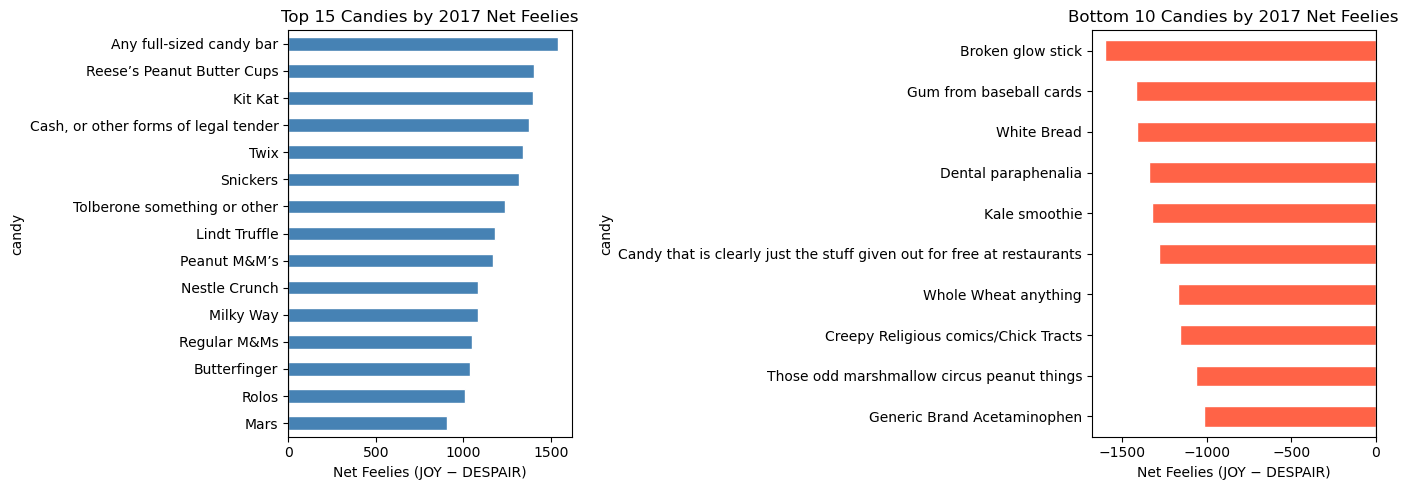

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Top 15 candies by 2017 net feelies
top15 = nf_pivot_common.sort_values(2017, ascending=False).head(15)
top15[2017].sort_values().plot(
    kind='barh', ax=axes[0], color='steelblue', edgecolor='white'
)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Top 15 Candies by 2017 Net Feelies')
axes[0].set_xlabel('Net Feelies (JOY − DESPAIR)')

# Chart 2: Bottom 10 candies by 2017 net feelies
bot10 = nf_pivot_common.sort_values(2017, ascending=True).head(10)
bot10[2017].sort_values(ascending=False).plot(
    kind='barh', ax=axes[1], color='tomato', edgecolor='white'
)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Bottom 10 Candies by 2017 Net Feelies')
axes[1].set_xlabel('Net Feelies (JOY − DESPAIR)')

plt.tight_layout()
plt.show()

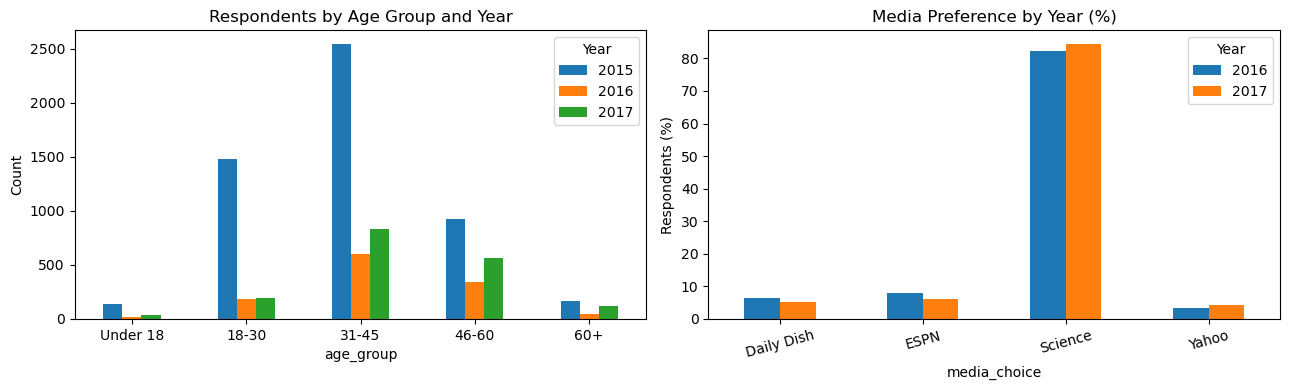

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Chart 3: Respondent age distribution across all years
age_counts = (
    all_respondents
    .dropna(subset=['age_group'])
    .groupby(['year', 'age_group'], observed=True)
    .size()
    .unstack(level=0, fill_value=0)
)
age_counts.plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Respondents by Age Group and Year')
axes[0].set_ylabel('Count')
axes[0].legend(title='Year')

# Chart 4: Media preference comparison 2016 vs 2017
media_pct.T.plot(kind='bar', ax=axes[1], rot=15)
axes[1].set_title('Media Preference by Year (%)')
axes[1].set_ylabel('Respondents (%)')
axes[1].legend(title='Year')

plt.tight_layout()
plt.show()

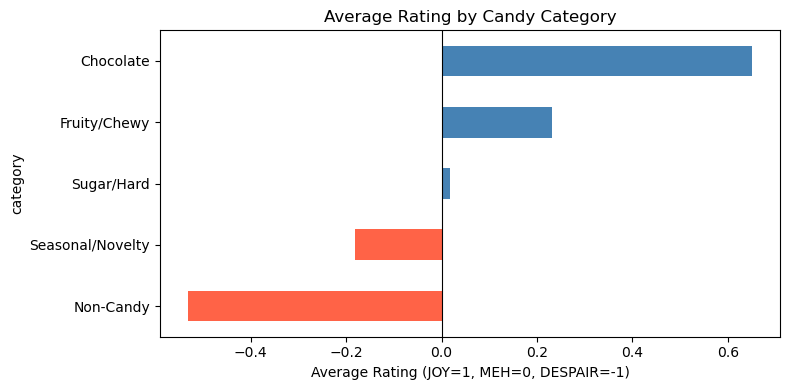

In [28]:
# Chart 5: Candy category average rating
fig, ax = plt.subplots(figsize=(8, 4))
cat_nf['avg_rating'].sort_values().plot(
    kind='barh', ax=ax,
    color=['tomato' if v < 0 else 'steelblue' for v in cat_nf['avg_rating'].sort_values()]
)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Average Rating by Candy Category')
ax.set_xlabel('Average Rating (JOY=1, MEH=0, DESPAIR=-1)')
plt.tight_layout()
plt.show()